# 05 · Cohort and retention analysis
Questions 6–11. The SQL matrix (q11) and an independent pandas implementation are computed and compared.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

In [2]:
o('q08_churn_rate_summary').T

,0
churned_customers,"8,156.00"
opening_base_customer_months,"532,454.00"
avg_monthly_churn_pct,1.53
annualised_churn_pct,16.90
implied_avg_lifetime_months,65.30


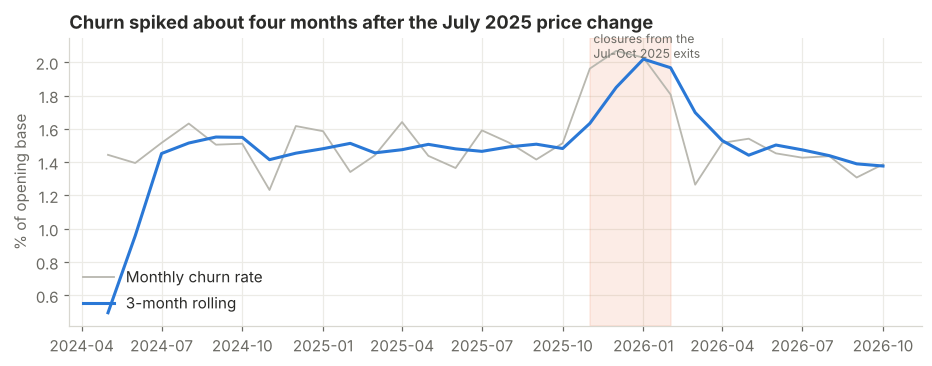

In [3]:
k = o("q02_monthly_kpi_trend"); k["month"] = pd.to_datetime(k.month); k = k[k.month >= "2024-05-01"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(k.month, k.churn_rate_pct, color=an.CONTEXT, lw=1.2, label="Monthly churn rate")
ax.plot(k.month, k.churn_rate_3m_pct, color=an.PRIMARY, label="3-month rolling")
ax.axvspan(pd.Timestamp("2025-11-01"), pd.Timestamp("2026-02-01"), color=an.HIGHLIGHT, alpha=.12)
ax.text(pd.Timestamp("2025-11-05"), k.churn_rate_pct.max() * .98, "closures from the\nJul-Oct 2025 exits", fontsize=8, color=an.INK_MUTED)
ax.set_ylabel("% of opening base"); ax.set_title("Churn spiked about four months after the July 2025 price change"); ax.legend(loc="lower left")
an.save(fig, "monthly_churn_rate");

,dim,grp,churned,base_customer_months,monthly_churn_pct,churn_rank_within_dim
5,county,Garissa,453,22326,2.03,1
6,county,Kilifi,587,29696,1.98,2
7,county,Turkana,453,23139,1.96,3
8,county,Uasin Gishu,498,30739,1.62,4
9,county,Nyeri,411,25810,1.59,5


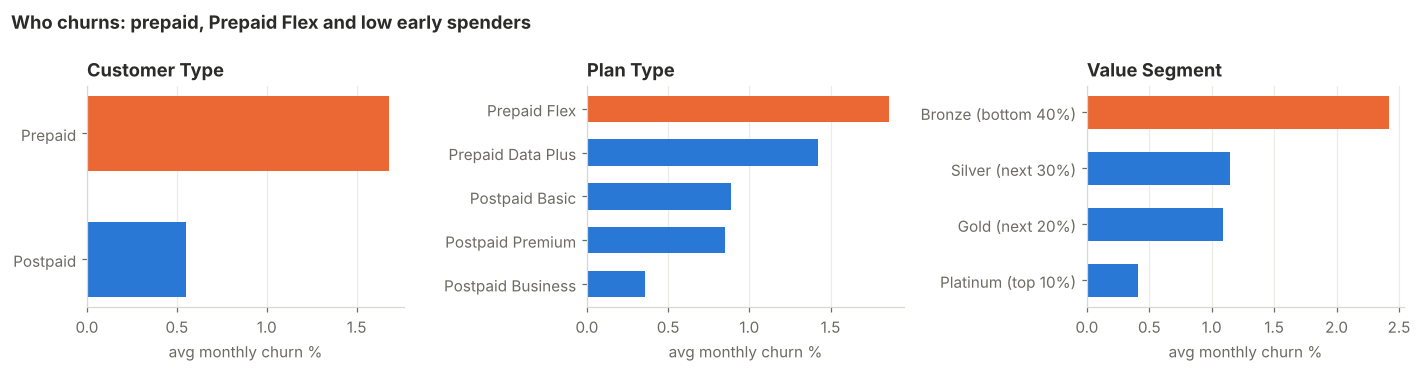

In [4]:
c = o("q09_churn_by_segment")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, dim in zip(axes, ["customer_type", "plan_type", "value_segment"]):
    d = c[c.dim == dim].sort_values("monthly_churn_pct")
    ax.barh(d.grp, d.monthly_churn_pct, color=[an.HIGHLIGHT if v == d.monthly_churn_pct.max() else an.PRIMARY for v in d.monthly_churn_pct], height=.6)
    ax.set_title(dim.replace("_", " ").title()); ax.set_xlabel("avg monthly churn %"); ax.grid(axis="y", visible=False)
fig.suptitle("Who churns: prepaid, Prepaid Flex and low early spenders", x=.01, ha="left", fontweight="bold")
fig.tight_layout(); an.save(fig, "churn_by_segment"); c[c.dim == 'county'].head(5)

The three counties with the highest churn (Garissa, Kilifi, Turkana) also have the highest network-complaint rates (notebook 07).

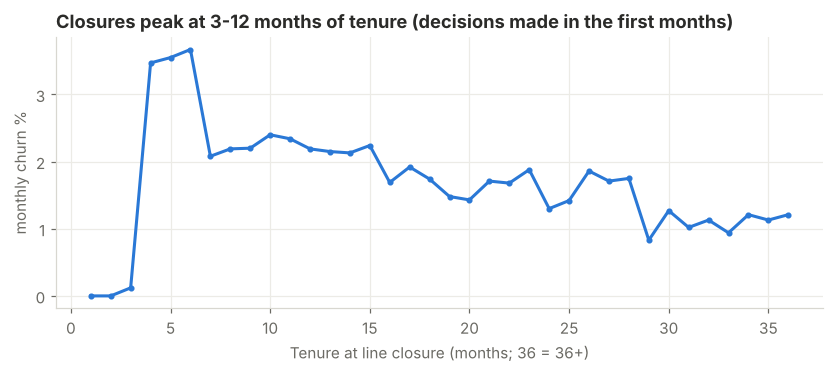

In [5]:
t = o("q10_churn_by_tenure")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t.tenure_month_capped_36, t.monthly_churn_pct, color=an.PRIMARY, marker="o", ms=3)
ax.set_xlabel("Tenure at line closure (months; 36 = 36+)"); ax.set_ylabel("monthly churn %")
ax.set_title("Closures peak at 3-12 months of tenure (decisions made in the first months)"); an.save(fig, "churn_by_tenure");

Closures can't happen before month 3–4, because of the 90-day rule. The peak at 3–12 months reflects customers who decided to leave **in their first months**, the classic early-life churn window.

## Cohort retention: SQL and pandas must agree

In [6]:
sql = o("q11_cohort_retention_matrix").pivot(index="cohort_month", columns="months_since_acquisition", values="retention_pct")
cm = query(engine, "SELECT customer_id, cohort_month, month, is_active FROM telco.mv_customer_month WHERE cohort_month >= DATE '2024-01-01'")
py = an.retention_matrix(cm, max_k=24)
sql.index = pd.to_datetime(sql.index); sql.columns = sql.columns.astype(int)
diff = (sql - py.round(1)).abs().max().max()
print(f"max absolute difference between SQL and pandas retention: {diff:.2f} percentage points")
assert diff < 0.11

max absolute difference between SQL and pandas retention: 0.10 percentage points


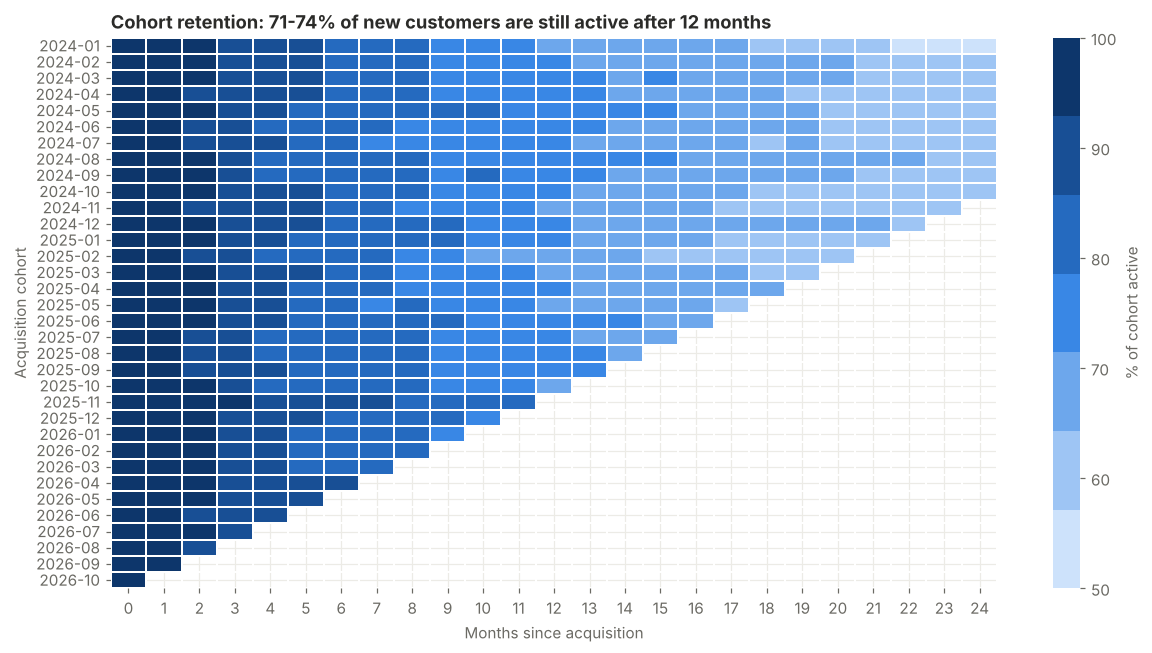

In [7]:
fig, ax = plt.subplots(figsize=(13, 6.5))
show = py.copy(); show.index = show.index.strftime("%Y-%m")
sns.heatmap(show.iloc[:, :25], cmap=sns.color_palette(an.SEQ_BLUES, as_cmap=True), vmin=50, vmax=100, ax=ax,
            cbar_kws={"label": "% of cohort active"}, linewidths=.3, linecolor="white", annot=False)
ax.set_xlabel("Months since acquisition"); ax.set_ylabel("Acquisition cohort")
ax.set_title("Cohort retention: 71-74% of new customers are still active after 12 months")
an.save(fig, "cohort_retention_heatmap");

In [8]:
o('q12_retention_milestones')

,acquisition_quarter,customers,active_after_1m_pct,active_after_3m_pct,active_after_6m_pct,active_after_12m_pct
0,2024-Q1,1395,96.70,92.00,84.70,73.30
1,2024-Q2,1336,96.30,90.30,82.30,73.50
2,2024-Q3,1363,97.40,90.00,83.20,73.80
3,2024-Q4,1462,96.50,91.00,83.60,71.80
4,2025-Q1,1342,97.30,90.20,83.50,71.00
5,2025-Q2,1313,97.30,90.00,82.90,72.60
6,2025-Q3,1330,97.30,88.20,81.90,72.30
7,2025-Q4,1507,97.60,92.00,84.70,71.20
8,2026-Q1,1381,97.20,89.90,83.30,NaN
9,2026-Q2,1304,96.60,91.50,86.30,NaN


**Reading the cohorts.** Retention is steady across cohorts: about 97% active after 1 month, about 90% after 3, about 83% after 6 and 71–74% after 12. The **2025-Q3 cohort** has the weakest 3-month figure. Those customers joined just as bundle prices rose, so their first renewals happened at the higher price.